# Práctica 3 · Parte 1 — Autoencoder convolucional
**Aprendizaje Profundo · Grado en Inteligencia Artificial · UDC · Curso 2026/2027**

**Integrantes:** _Sneshanka Blanca Andrés Ochoa_, _Pedro José Agrelo Márquez_

---

En esta parte 1 solo se construye el **autoencoder** (encoder + decoder):
- Objetivo: reconstruir la misma imagen de entrada 48×48×3 en [0, 1]
- Pérdida: `MSE(x, D(E(x)))`.
- Experimento: comparar **d = 32** y **d = 128** (tamaño del vector latente).
- Se guardan los datos separados por circuito y se crea la referencia "repetir la última imagen".

## Configuración del entorno
Esta celda monta Drive (si estamos en Colab), entra en la carpeta del proyecto, descomprime los ficheros si hace falta y comprueba que están todos.

In [ ]:
import os, sys

# Ruta de la carpeta del proyecto en Google Drive
PROJECT_DIR = "/content/drive/MyDrive/AP/P3"

# Detectamos si estamos en Colab: el módulo google.colab solo existe allí
try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    drive.mount("/content/drive")             # pide permiso la primera vez y monta Drive
    os.makedirs(PROJECT_DIR, exist_ok=True)   
    os.chdir(PROJECT_DIR)                     # a partir de aquí, las rutas relativas apuntan a Drive
    # Si el zip de ayuda está en la carpeta pero no se ha descomprimido, lo descomprime
    if not os.path.exists("dataset.py") and os.path.exists("ficheros_ayuda.zip"):
        import zipfile
        zipfile.ZipFile("ficheros_ayuda.zip").extractall(".")

# Añadimos la carpeta actual a la ruta de búsqueda de módulos para poder hacer "import dataset", etc.
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

print("Directorio de trabajo:", os.getcwd())

# Comprobación: sin estos ficheros el notebook no puede funcionar
needed = ["dataset.py", "carracing48.py", "metric.py", "requirements.txt"]
missing = [f for f in needed if not os.path.exists(f)]
assert not missing, f"Faltan ficheros en la carpeta: {missing}"
print("Ficheros encontrados")

Directorio de trabajo: /home/snesh/AP/P3
Ficheros encontrados


### Dependencias
Instalamos `swig` (lo necesita Box2D para compilar) y después el `requirements.txt`. En Colab hay que ejecutar esto cada vez que se abre el notebook.

In [3]:
# Box2D a veces necesita compilarse: instalar swig antes evita el error de compilación
%pip install -q swig
# Dependencias indicadas por el profesor: gymnasium[box2d], scikit-image y pandas
%pip install -q -r requirements.txt

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


### Librerías, semilla y carpetas
- Variables `SDL_*`: Pygame no tiene pantalla en Colab, así que usa controladores "vacíos".
- `SEED = 42`: fija todas las semillas para que los resultados sean repetibles.
- Carpetas: `datos/`, `modelos/` y `resultados/`.
- Acciones (enteros): 0 nada, 1 derecha, 2 izquierda, 3 acelerar, 4 frenar.

In [ ]:
import os
os.environ.setdefault("SDL_VIDEODRIVER", "dummy")   # Pygame sin pantalla
os.environ.setdefault("SDL_AUDIODRIVER", "dummy")   # Pygame sin audio
os.environ.setdefault("KERAS_BACKEND", "tensorflow")

# Para la ejecución en GPU
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3" # Silencia warnings
os.environ["TF_FORCE_GPU_ALLOW_GROWTH"] = "true" # Evita errores de memoria al no reservarla de golpe
os.environ["TF_DETERMINISTIC_OPS"] = "1" # Operaciones deterministas para GPU
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0" # Elimina un warning 

import json, time, platform
import numpy as np
import matplotlib.pyplot as plt
import keras
from keras import layers

from dataset import generate_sequences, CONTEXT_LENGTH, PREDICTION_LENGTH  # 12 y 24
from carracing48 import make_env
from metric import visual_metrics

SEED = 42
keras.utils.set_random_seed(SEED)   # Python, NumPy y backend

DATA_DIR, MODEL_DIR, RESULTS_DIR = "datos", "modelos", "resultados"
for d in (DATA_DIR, MODEL_DIR, RESULTS_DIR):
    os.makedirs(d, exist_ok=True)

ACTION_NAMES = {0: "nada", 1: "derecha", 2: "izquierda", 3: "acelerar", 4: "frenar"}

import tensorflow as tf

print("Python", platform.python_version(), "| Keras", keras.__version__, "| backend", keras.backend.backend(), "| TF", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU") or "no disponible")

Python 3.12.3 | Keras 3.16.0.dev2026110503 | backend tensorflow | TF 2.23.0-dev20261104
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Datos
`generate_sequences(seed, n)` crea `n` circuitos aleatorios y conduce con una política automática. Devuelve:
- `frames` (N, 96, 48, 48, 3): 96 fotogramas consecutivos por circuito (`uint8`, 0–255).
- `actions` (N, 95): la acción `a_j` lleva de `frames[j]` a `frames[j+1]`.

**Partición por circuito** (semillas distintas → circuitos distintos):
- Entrenamiento: semilla 1234, 128 circuitos → 12 288 fotogramas.
- Validación: semilla 5678, 32 circuitos → 3 072 fotogramas.

Así la validación mide cómo generaliza el modelo a **circuitos nuevos**.

Generar datos tarda aproximadamente 20 min (simulador en CPU), por eso se guardan los arrays en `datos/` y se reutilizan en todas las partes. Los datos de Kaggle no se usan para entrenar.

In [ ]:
# Semillas distintas -> circuitos distintos en train y validación
TRAIN_SEED, VALID_SEED = 1234, 5678
N_TRAIN, N_VALID = 128, 32

def load_or_generate(name, seed, n):
    """Carga datos/<name>.npz si existe; si no, lo genera y lo guarda."""
    path = os.path.join(DATA_DIR, f"{name}.npz")
    meta_path = os.path.join(DATA_DIR, f"{name}_meta.json")
    if os.path.exists(path):
        data = np.load(path)
        print(f"{name}: cargado de {path}")
        return {"frames": data["frames"], "actions": data["actions"]}
    t0 = time.time()
    
    def progress(done, total):
        if done % 8 == 0 or done == total:
            print(f"  {name}: {done}/{total} secuencias ({time.time()-t0:.0f}s)", flush=True)
            
    data, meta = generate_sequences(seed=seed, n_sequences=n,
                                    return_metadata=True, progress=progress)
    np.savez_compressed(path, **data)
    with open(meta_path, "w") as f:   # metadatos para reproducibilidad
        json.dump({"seed": seed, "n_sequences": n, "generation_seconds": time.time()-t0,
                   "python": platform.python_version(), "circuits": meta}, f, indent=1)
    print(f"{name}: generado en {time.time()-t0:.0f}s y guardado en {path}")
    return data

train = load_or_generate("train", TRAIN_SEED, N_TRAIN)
valid = load_or_generate("valid", VALID_SEED, N_VALID)

for name, d in [("train", train), ("valid", valid)]:
    print(f"{name}: frames {d['frames'].shape} {d['frames'].dtype} | actions {d['actions'].shape} {d['actions'].dtype}")

  train: 8/128 secuencias (26s)
  train: 16/128 secuencias (49s)
  train: 24/128 secuencias (79s)
  train: 32/128 secuencias (105s)
  train: 40/128 secuencias (129s)
  train: 48/128 secuencias (154s)
  train: 56/128 secuencias (181s)
  train: 64/128 secuencias (207s)
  train: 72/128 secuencias (232s)
  train: 80/128 secuencias (258s)
  train: 88/128 secuencias (284s)
  train: 96/128 secuencias (313s)
  train: 104/128 secuencias (339s)
  train: 112/128 secuencias (361s)
  train: 120/128 secuencias (386s)
  train: 128/128 secuencias (409s)
train: generado en 410s y guardado en datos/train.npz
  valid: 8/32 secuencias (28s)
  valid: 16/32 secuencias (56s)
  valid: 24/32 secuencias (86s)
  valid: 32/32 secuencias (115s)
valid: generado en 115s y guardado en datos/valid.npz
train: frames (128, 96, 48, 48, 3) uint8 | actions (128, 95) int64
valid: frames (32, 96, 48, 48, 3) uint8 | actions (32, 95) int64


### Comprobaciones
Formas y tipos correctos, T−1 acciones por secuencia, acciones entre 0 y 4, y **ningún circuito compartido** entre entrenamiento y validación (resultado: 0).

In [8]:
# Formatos correctos
for name, d in [("train", train), ("valid", valid)]:
    f, a = d["frames"], d["actions"]
    assert f.ndim == 5 and f.shape[2:] == (48, 48, 3) and f.dtype == np.uint8
    assert a.shape == (f.shape[0], f.shape[1] - 1), "Debe haber T-1 acciones por secuencia"
    assert a.min() >= 0 and a.max() <= 4

# Semillas de los circuitos de cada partición (guardadas en los metadatos)
def circuits(name):
    with open(os.path.join(DATA_DIR, f"{name}_meta.json")) as fh:
        return {c["track_seed"] for c in json.load(fh)["circuits"]}

# Ningún circuito en train y valid a la vez
if os.path.exists(os.path.join(DATA_DIR, "train_meta.json")):
    shared = circuits("train") & circuits("valid")
    print("Circuitos compartidos entre train y valid:", len(shared))
    assert not shared
print("Formatos correctos")

Circuitos compartidos entre train y valid: 0
Formatos correctos


## Inspección de una secuencia
Miramos una secuencia para entender los datos. 

`actions[i, j]` es la acción que lleva de `frames[i, j]` a `frames[i, j+1]`. Las acciones solo se inspeccionan; el autoencoder no las usa.

En cada imagen aparece la pista gris, hierba verde, bordillos rojo/blanco en las curvas, el coche rojo siempre abajo en el centro (la cámara lo sigue) y una barra negra inferior con velocidad, ABS, dirección (verde) y giroscopio (rojo).

Fotogramas: (96, 48, 48, 3) | acciones: (95,)
Primeras 20 acciones: ['derecha', 'acelerar', 'izquierda', 'acelerar', 'izquierda', 'acelerar', 'izquierda', 'acelerar', 'izquierda', 'izquierda', 'izquierda', 'acelerar', 'derecha', 'izquierda', 'izquierda', 'acelerar', 'izquierda', 'acelerar', 'frenar', 'acelerar']


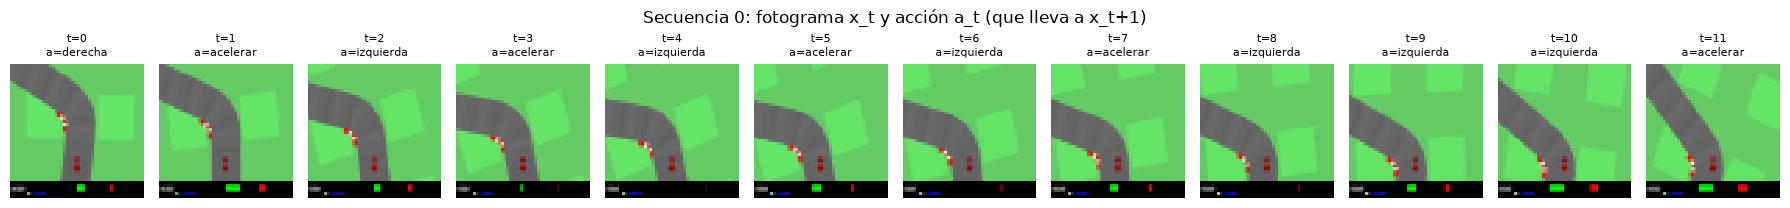

In [9]:
i = 0  # secuencia que inspeccionamos
frames_i, actions_i = train["frames"][i], train["actions"][i]
print("Fotogramas:", frames_i.shape, "| acciones:", actions_i.shape)
print("Primeras 20 acciones:", [ACTION_NAMES[a] for a in actions_i[:20]])

# 12 fotogramas consecutivos con su acción
fig, axes = plt.subplots(1, 12, figsize=(18, 2.2))
for j, ax in enumerate(axes):
    ax.imshow(frames_i[j], interpolation="nearest")
    ax.set_title(f"t={j}\na={ACTION_NAMES[actions_i[j]]}", fontsize=8)
    ax.axis("off")
plt.suptitle(f"Secuencia {i}: fotograma x_t y acción a_t (que lleva a x_t+1)")
plt.tight_layout(); plt.show()

### Alineación y distribución de acciones
Para cada acción se muestra `x_j`, `x_{j+1}` y su diferencia: al acelerar la pista baja; al girar la escena rota (tercera imagen de cada fila).

La acción más frecuente es **acelerar (~50 %)**; **nada** y **frenar** son raras (~2 %). En las partes 3–5 el predictor verá pocos ejemplos de esas dos acciones.

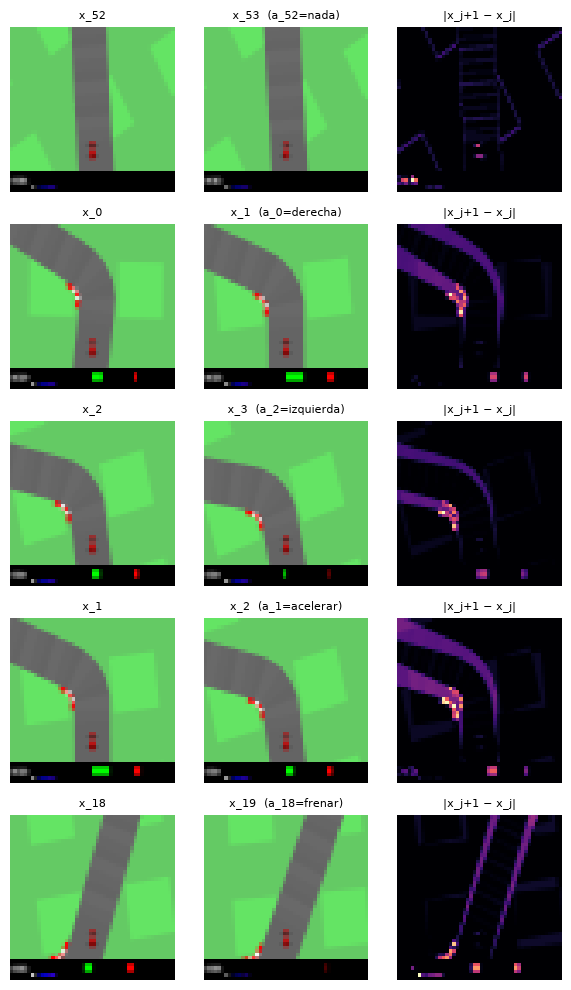

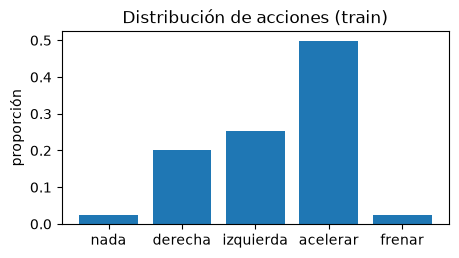

In [10]:
# Para cada acción: primera aparición j -> x_j, x_{j+1} y su diferencia
js = [int(np.where(actions_i == a)[0][0]) for a in range(5) if (actions_i == a).any()]
fig, axes = plt.subplots(len(js), 3, figsize=(6, 2 * len(js)))
for row, j in zip(np.atleast_2d(axes), js):
    diff = np.abs(frames_i[j + 1].astype(int) - frames_i[j].astype(int)).mean(-1)  # int: evita overflow de uint8
    row[0].imshow(frames_i[j], interpolation="nearest"); row[0].set_title(f"x_{j}", fontsize=8)
    row[1].imshow(frames_i[j + 1], interpolation="nearest"); row[1].set_title(f"x_{j+1}  (a_{j}={ACTION_NAMES[actions_i[j]]})", fontsize=8)
    row[2].imshow(diff, cmap="magma"); row[2].set_title("|x_j+1 − x_j|", fontsize=8)
    for ax in row: ax.axis("off")
plt.tight_layout(); plt.show()

# Distribución de acciones en entrenamiento
counts = np.bincount(train["actions"].ravel(), minlength=5)
plt.figure(figsize=(5, 2.5))
plt.bar([ACTION_NAMES[k] for k in range(5)], counts / counts.sum())
plt.title("Distribución de acciones (train)"); plt.ylabel("proporción"); plt.show()

### Exploración del entorno
`make_env()` con `reset`, `step` y `render`: aplicamos 10 pasos acelerando, 5 a la izquierda y 5 a la derecha. Solo es exploración; estas imágenes no se usan para entrenar.

Observación: (48, 48, 3) uint8


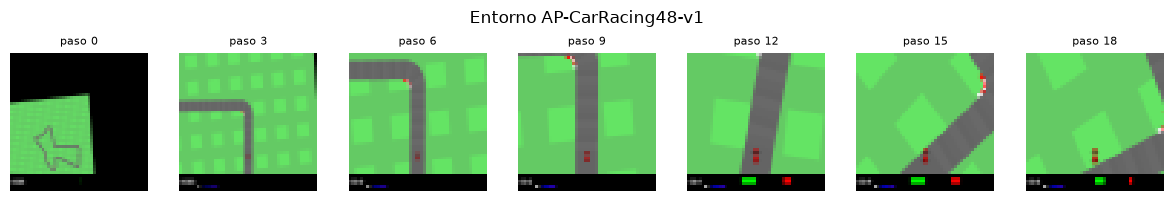

In [11]:
# Exploración del entorno: reset, step, render
env = make_env(seed=0)
obs, _ = env.reset(seed=0)
seq_env = [obs]
for a in [3] * 10 + [2] * 5 + [1] * 5:     # acelerar, izquierda, derecha
    obs, reward, term, trunc, _ = env.step(a)
    seq_env.append(obs)
assert np.array_equal(env.render(), obs)   # render() = última observación
env.close()
print("Observación:", obs.shape, obs.dtype)

fig, axes = plt.subplots(1, 7, figsize=(12, 2))
for ax, j in zip(axes, range(0, 21, 3)):
    ax.imshow(seq_env[j], interpolation="nearest"); ax.set_title(f"paso {j}", fontsize=8); ax.axis("off")
plt.suptitle("Entorno AP-CarRacing48-v1"); plt.tight_layout(); plt.show()

## Referencia sin entrenamiento: repetir la última imagen
Predice los 24 fotogramas futuros copiando el último fotograma observado: `x̂_{t+1} = … = x̂_{t+24} = x_t`. No aprende nada. Sirve de **línea base**: un predictor que no la supere no aporta nada (es lo que hace `sample_submission.csv`).

**Ventanas:** una ventana que empieza en `s` tiene contexto `x_s…x_{s+11}` (12), objetivos `x_{s+12}…x_{s+35}` (24) y acciones `a_s…a_{s+34}` (35). Con T = 96 y paso 1 hay 61 ventanas por circuito. Aquí usamos **paso 12** (192 ventanas en validación) para que sea más rápido; las ventanas nunca cruzan circuitos.

**Métricas** (`visual_metrics`, imágenes en [0, 1]): **MSE** (error por píxel), **SSIM** (similitud estructural, 1 = idéntica), **gradiente** (bordes) y **score** de Kaggle (`0,8·(1−SSIM)/2 + 0,2·G`; 0 = perfecto; menor es mejor).

**Resultado:** score 0,101 · SSIM 0,751 · MSE 0,0156. El score sube rápido en los primeros pasos (0,060 en h = 1) y se estabiliza en ~0,10–0,107 desde h ≈ 5.

Ventanas válidas por circuito con paso 1: 61
Ventanas de evaluación: (192, 12, 48, 48, 3) (192, 24, 48, 48, 3) (192, 35)
Repetir la última imagen (24 pasos): {'score': 0.101, 'ssim': 0.7511, 'gradient': 0.0071, 'mse': 0.0156}


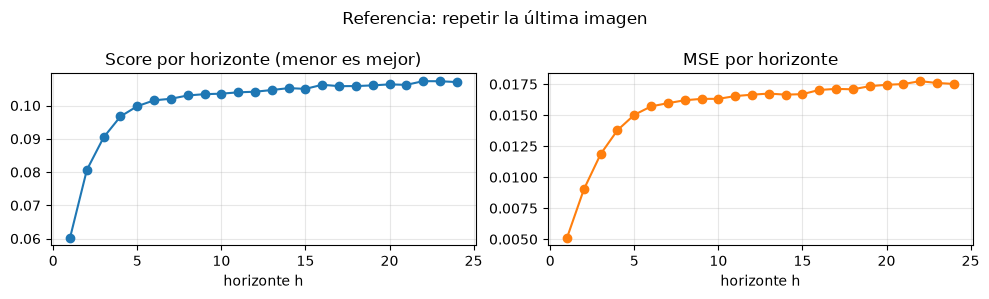

In [12]:
def make_windows(frames, actions, stride=1):
    """Ventanas de 12 imágenes de contexto + 24 objetivos + 35 acciones (sin cruzar circuitos)."""
    T = frames.shape[1]
    starts = range(0, T - (CONTEXT_LENGTH + PREDICTION_LENGTH) + 1, stride)  # T-35 ventanas con paso 1
    ctx, tgt, act = [], [], []
    for n in range(frames.shape[0]):   # cada secuencia = un circuito
        for s in starts:
            ctx.append(frames[n, s:s + CONTEXT_LENGTH])                                       # x_s .. x_{s+11}
            tgt.append(frames[n, s + CONTEXT_LENGTH:s + CONTEXT_LENGTH + PREDICTION_LENGTH])  # x_{s+12} .. x_{s+35}
            act.append(actions[n, s:s + CONTEXT_LENGTH + PREDICTION_LENGTH - 1])              # a_s .. a_{s+34}
    return np.stack(ctx), np.stack(tgt), np.stack(act)

def repeat_last_baseline(context):
    """Referencia sin entrenar: repite el último fotograma 24 veces."""
    return np.repeat(context[:, -1:], PREDICTION_LENGTH, axis=1)

T = valid["frames"].shape[1]
print("Ventanas válidas por circuito con paso 1:", T - 35)   # 61

# Ventanas de validación con paso 12: 6 por circuito x 32 = 192
ctx_v, tgt_v, act_v = make_windows(valid["frames"], valid["actions"], stride=12)
# Alineación: el primer objetivo sigue al último fotograma del contexto
assert np.array_equal(tgt_v[0, 0], valid["frames"][0, 12]) and np.array_equal(ctx_v[0, -1], valid["frames"][0, 11])
print("Ventanas de evaluación:", ctx_v.shape, tgt_v.shape, act_v.shape)

# Predicción y normalización a [0, 1]
pred_v = repeat_last_baseline(ctx_v)
Y, P = tgt_v.astype("float32") / 255, pred_v.astype("float32") / 255
baseline_global = visual_metrics(Y, P)
baseline_by_h = [visual_metrics(Y[:, h], P[:, h]) for h in range(PREDICTION_LENGTH)]  # una métrica por horizonte
print("Repetir la última imagen (24 pasos):", {k: round(v, 4) for k, v in baseline_global.items()})

# Guardar para comparar en las partes 3-5
np.savez_compressed(os.path.join(RESULTS_DIR, "baseline_repeat_last.npz"),
                    score=[m["score"] for m in baseline_by_h], ssim=[m["ssim"] for m in baseline_by_h],
                    mse=[m["mse"] for m in baseline_by_h], window_stride=12)

# Error por horizonte
hs = np.arange(1, PREDICTION_LENGTH + 1)
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(hs, [m["score"] for m in baseline_by_h], marker="o"); ax[0].set_title("Score por horizonte (menor es mejor)")
ax[1].plot(hs, [m["mse"] for m in baseline_by_h], marker="o", color="C1"); ax[1].set_title("MSE por horizonte")
for a in ax: a.set_xlabel("horizonte h"); a.grid(alpha=.3)
plt.suptitle("Referencia: repetir la última imagen"); plt.tight_layout(); plt.show()

### Ejemplo visual de la referencia
Fila 1: imagen real. Fila 2: predicción (siempre la misma). Fila 3: error. El error crece con el horizonte porque la pista real se aleja de la imagen congelada.

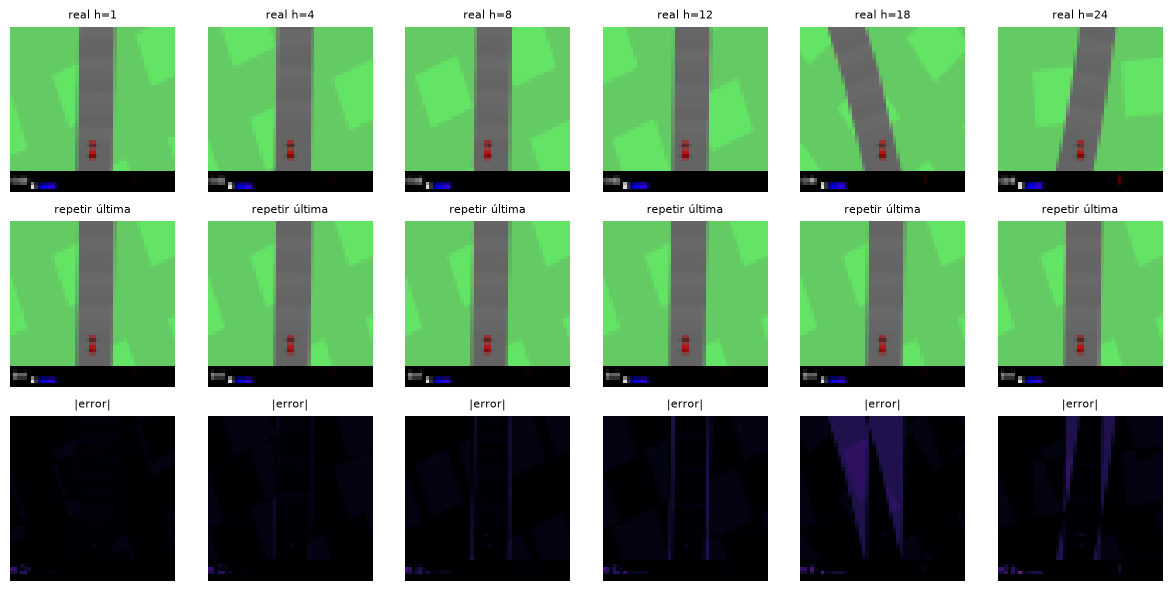

In [13]:
# Realidad, predicción y error en varios horizontes (índices 0..23 = h 1..24)
w, show_h = 0, [0, 3, 7, 11, 17, 23]
fig, axes = plt.subplots(3, len(show_h), figsize=(12, 6))
for c, h in enumerate(show_h):
    axes[0, c].imshow(Y[w, h], interpolation="nearest"); axes[0, c].set_title(f"real h={h+1}", fontsize=8)
    axes[1, c].imshow(P[w, h], interpolation="nearest"); axes[1, c].set_title("repetir última", fontsize=8)
    axes[2, c].imshow(np.abs(Y[w, h] - P[w, h]).mean(-1), cmap="magma", vmin=0, vmax=1); axes[2, c].set_title("|error|", fontsize=8)
for a in axes.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

## 4. Datos para el autoencoder
El autoencoder trabaja con fotogramas sueltos, así que juntamos las dos primeras dimensiones y normalizamos a [0, 1]:
- `X_train`: (128·96, 48, 48, 3) = **12 288** imágenes.
- `X_val`: (32·96, 48, 48, 3) = **3 072** imágenes.

Además se eligen **512 imágenes de validación fijas** (con semilla) y se guardan en `datos/eval_images.npz`. Se reutilizarán en la parte 2 para comparar sobre las mismas imágenes.

In [14]:
# Fotogramas sueltos: (N, T, 48, 48, 3) -> (N*T, 48, 48, 3), en [0, 1]
X_train = train["frames"].reshape(-1, 48, 48, 3).astype("float32") / 255.0
X_val = valid["frames"].reshape(-1, 48, 48, 3).astype("float32") / 255.0
print("X_train:", X_train.shape, f"[{X_train.min():.2f}, {X_train.max():.2f}]")
print("X_val:  ", X_val.shape)

# 512 imágenes de validación fijas (se reutilizan en la parte 2)
eval_path = os.path.join(DATA_DIR, "eval_images.npz")
if os.path.exists(eval_path):
    eval_idx = np.load(eval_path)["indices"]
else:
    eval_idx = np.sort(np.random.default_rng(SEED).choice(len(X_val), size=512, replace=False))
    np.savez_compressed(eval_path, indices=eval_idx, images=valid["frames"].reshape(-1, 48, 48, 3)[eval_idx])
X_eval = X_val[eval_idx]
print("Imágenes de evaluación fijas:", X_eval.shape)

X_train: (12288, 48, 48, 3) [0.00, 0.99]
X_val:   (3072, 48, 48, 3)
Imágenes de evaluación fijas: (512, 48, 48, 3)


## Arquitectura del autoencoder
Un autoencoder **comprime** la imagen en un vector `z` (cuello de botella) y la **reconstruye**. Al tener `z` mucho menos números que la imagen, solo conserva lo más importante. Usamos convoluciones porque aprovechan patrones locales con pocos parámetros.

- **Stride 2** reduce a la mitad alto y ancho; **Conv2DTranspose con stride 2** lo duplica.
- Al bajar la resolución, aumentan los filtros (32 → 64 → 128).
- El latente es **lineal** para que `z` pueda tomar cualquier valor real.
- La sigmoide final da valores en [0, 1], como las imágenes.
- Encoder y decoder son **modelos separados** para guardarlos y reutilizarlos.

Con d = 32: encoder 286 912 parámetros + decoder 438 947 = 725 859. Compresión: 6912 → 32 valores (**216×**).

In [15]:
def build_encoder(latent_dim):
    """Imagen (48,48,3) -> latente (latent_dim,)."""
    inp = keras.Input((48, 48, 3), name="imagen")
    x = layers.Conv2D(32, 3, strides=2, padding="same", activation="relu", name="enc_conv1")(inp)  # 24x24x32
    x = layers.Conv2D(32, 3, padding="same", activation="relu", name="enc_conv1b")(x)              # 24x24x32
    x = layers.Conv2D(64, 3, strides=2, padding="same", activation="relu", name="enc_conv2")(x)    # 12x12x64
    x = layers.Conv2D(64, 3, padding="same", activation="relu", name="enc_conv2b")(x)              # 12x12x64
    x = layers.Conv2D(128, 3, strides=2, padding="same", activation="relu", name="enc_conv3")(x)   # 6x6x128
    x = layers.Flatten(name="enc_flatten")(x)                                                      # 4608
    z = layers.Dense(latent_dim, name="latente")(x)                                                # d, lineal
    return keras.Model(inp, z, name=f"encoder_d{latent_dim}")

def build_decoder(latent_dim):
    """Latente (latent_dim,) -> imagen (48,48,3) en [0,1]."""
    z = keras.Input((latent_dim,), name="latente")
    x = layers.Dense(6 * 6 * 128, activation="relu", name="dec_dense")(z)                                # 4608
    x = layers.Reshape((6, 6, 128), name="dec_reshape")(x)                                               # 6x6x128
    x = layers.Conv2DTranspose(128, 3, strides=2, padding="same", activation="relu", name="dec_up1")(x)  # 12x12x128
    x = layers.Conv2D(64, 3, padding="same", activation="relu", name="dec_conv1")(x)                     # 12x12x64
    x = layers.Conv2DTranspose(64, 3, strides=2, padding="same", activation="relu", name="dec_up2")(x)   # 24x24x64
    x = layers.Conv2D(32, 3, padding="same", activation="relu", name="dec_conv2")(x)                     # 24x24x32
    x = layers.Conv2DTranspose(32, 3, strides=2, padding="same", activation="relu", name="dec_up3")(x)   # 48x48x32
    out = layers.Conv2D(3, 3, padding="same", activation="sigmoid", name="reconstruccion")(x)            # 48x48x3
    return keras.Model(z, out, name=f"decoder_d{latent_dim}")

def build_autoencoder(latent_dim):
    """Autoencoder D(E(x)); devuelve también encoder y decoder por separado."""
    enc, dec = build_encoder(latent_dim), build_decoder(latent_dim)
    inp = keras.Input((48, 48, 3))
    ae = keras.Model(inp, dec(enc(inp)), name=f"autoencoder_d{latent_dim}")
    return ae, enc, dec

# Modelo de ejemplo solo para ver la arquitectura
_ae, _enc, _dec = build_autoencoder(32)
_enc.summary(); _dec.summary()
print(f"Compresión con d=32: {48*48*3} valores → 32 ({48*48*3/32:.0f}x)")

W0000 00:00:1795197091.338686   19514 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
I0000 00:00:1795197091.339614   19514 gpu_device.cc:2038] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5563 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


Model: "encoder_d32"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagen (InputLayer)             │ (None, 48, 48, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_conv1 (Conv2D)              │ (None, 24, 24, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_conv1b (Conv2D)             │ (None, 24, 24, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_conv2 (Conv2D)              │ (None, 12, 12, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_conv2b (Conv2D)             │ (None, 12, 12, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_conv3 (Conv2D)              │ (None, 6, 6, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_flatten (Flatten)           │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latente (Dense)                 │ (None, 32)             │       147,488 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 286,912 (1.09 MB)

 Trainable params: 286,912 (1.09 MB)

 Non-trainable params: 0 (0.00 B)

... (2 outputs left out)

 Total params: 438,947 (1.67 MB)

 Trainable params: 438,947 (1.67 MB)

 Non-trainable params: 0 (0.00 B)

Compresión con d=32: 6912 valores → 32 (216x)


## Entrenamiento y comparación de d = 32 frente a d = 128
Solo cambia el tamaño del vector latente. Todo lo demás es igual: misma arquitectura (salvo las dos capas densas que dependen del tamaño), mismos datos, misma semilla, Adam con lr = 0,001, lotes de 128 y 60 épocas.

- Pérdida: **MSE**. Se entrena con `fit(X_train, X_train)` y se valida con `(X_val, X_val)`.
- **ModelCheckpoint** guarda los pesos de la mejor época en validación, y al final se cargan.
- Se guardan encoder y decoder por separado en `modelos/`.
- **Tiempos:** antes del bucle se hace un entrenamiento de calentamiento (se descarta) para que el primer modelo no pague la compilación de TensorFlow y la comparación de tiempos sea justa.
- Se registran parámetros, tiempos, mejor época, historial y métricas en `resultados/parte1_resultados.json`.

In [16]:
LATENT_DIMS = [32, 128]                  # los dos tamaños a comparar
EPOCHS, BATCH_SIZE, LR = 60, 128, 1e-3   # mismo presupuesto para ambos

# Calentamiento de GPU (modelo descartado) para que el primer modelo no pague la compilación
_w, _, _ = build_autoencoder(32)
_w.compile(optimizer="adam", loss="mse")
_w.fit(X_train[:1024], X_train[:1024], epochs=1, batch_size=BATCH_SIZE, verbose=0)
_w.predict(X_val[:512], verbose=0)
del _w

results, models = {}, {}
for d in LATENT_DIMS:
    keras.utils.set_random_seed(SEED)    # misma inicialización y barajado
    ae, enc, dec = build_autoencoder(d)
    ae.compile(optimizer=keras.optimizers.Adam(LR), loss="mse")
    # Guarda los pesos solo si mejora la pérdida de validación
    ckpt = os.path.join(MODEL_DIR, f"ae_d{d}_best.weights.h5")
    callbacks = [keras.callbacks.ModelCheckpoint(ckpt, monitor="val_loss", save_best_only=True,
                                                 save_weights_only=True)]
    print(f"\n=== d = {d} | parámetros: {ae.count_params():,} ===")
    t0 = time.time()
    # Entrada y objetivo son la misma imagen
    hist = ae.fit(X_train, X_train, validation_data=(X_val, X_val), epochs=EPOCHS,
                  batch_size=BATCH_SIZE, shuffle=True, callbacks=callbacks, verbose=2)
    train_time = time.time() - t0
    ae.load_weights(ckpt)                # mejor época en validación

    # Encoder y decoder por separado para las partes siguientes
    enc.save(os.path.join(MODEL_DIR, f"encoder_d{d}.keras"))
    dec.save(os.path.join(MODEL_DIR, f"decoder_d{d}.keras"))

    # Tiempo de inferencia (tras un predict de calentamiento)
    ae.predict(X_val[:512], batch_size=512, verbose=0)
    t0 = time.time()
    rec_val = ae.predict(X_val, batch_size=512, verbose=0)
    infer_time = time.time() - t0
    m_val = visual_metrics(X_val, np.clip(rec_val, 0, 1))
    models[d] = (ae, enc, dec)
    results[d] = {"latent_dim": d, "params_encoder": enc.count_params(), "params_decoder": dec.count_params(),
                  "params_total": ae.count_params(), "train_time_s": train_time,
                  "infer_time_val_s": infer_time, "best_epoch": int(np.argmin(hist.history["val_loss"])) + 1,
                  "history": hist.history, **{f"val_{k}": v for k, v in m_val.items()}}
    print(f"d={d}: MSE val={m_val['mse']:.5f} | SSIM={m_val['ssim']:.4f} | score={m_val['score']:.4f} | {train_time:.0f}s")

with open(os.path.join(RESULTS_DIR, "parte1_resultados.json"), "w") as f:
    json.dump({str(k): v for k, v in results.items()}, f, indent=1)

I0000 00:00:1795197125.500662   29008 cuda_dnn.cc:503] Loaded cuDNN version 92700



=== d = 32 | parámetros: 725,859 ===
Epoch 1/60
96/96 - 5s - 49ms/step - loss: 0.0278 - val_loss: 0.0097
Epoch 2/60
96/96 - 3s - 26ms/step - loss: 0.0060 - val_loss: 0.0032
Epoch 3/60
96/96 - 2s - 26ms/step - loss: 0.0026 - val_loss: 0.0023
Epoch 4/60
96/96 - 2s - 26ms/step - loss: 0.0022 - val_loss: 0.0021
Epoch 5/60
96/96 - 2s - 26ms/step - loss: 0.0020 - val_loss: 0.0020
Epoch 6/60
96/96 - 2s - 26ms/step - loss: 0.0019 - val_loss: 0.0019
Epoch 7/60
96/96 - 2s - 25ms/step - loss: 0.0018 - val_loss: 0.0018
Epoch 8/60
96/96 - 3s - 27ms/step - loss: 0.0017 - val_loss: 0.0017
Epoch 9/60
96/96 - 2s - 26ms/step - loss: 0.0016 - val_loss: 0.0016
Epoch 10/60
96/96 - 2s - 26ms/step - loss: 0.0016 - val_loss: 0.0016
Epoch 11/60
96/96 - 3s - 26ms/step - loss: 0.0015 - val_loss: 0.0015
Epoch 12/60
96/96 - 3s - 27ms/step - loss: 0.0014 - val_loss: 0.0015
Epoch 13/60
96/96 - 3s - 26ms/step - loss: 0.0014 - val_loss: 0.0014
Epoch 14/60
96/96 - 3s - 26ms/step - loss: 0.0013 - val_loss: 0.0014
Epoch

### Curvas y tabla resumen
Curvas de pérdida (escala logarítmica para ver mejor los cambios) y tabla con parámetros, tiempos y métricas.

**Qué se observa:**
- **d = 32** mejora despacio y se estanca (mejor época 59).
- **d = 128** tiene una **caída brusca hacia la época 32** (MSE ≈ 1,1·10⁻³ → 5·10⁻⁴): ahí aprende a reconstruir el indicador de dirección de la barra inferior (se puede ver en la celda siguiente de reconstrucción). Sobreajusta un poco al final (su mejor época es la 53), por eso usamos los pesos guardados.
- Los tiempos de entrenamiento son casi iguales: 217 s (d = 128) frente a 210 s (d = 32).

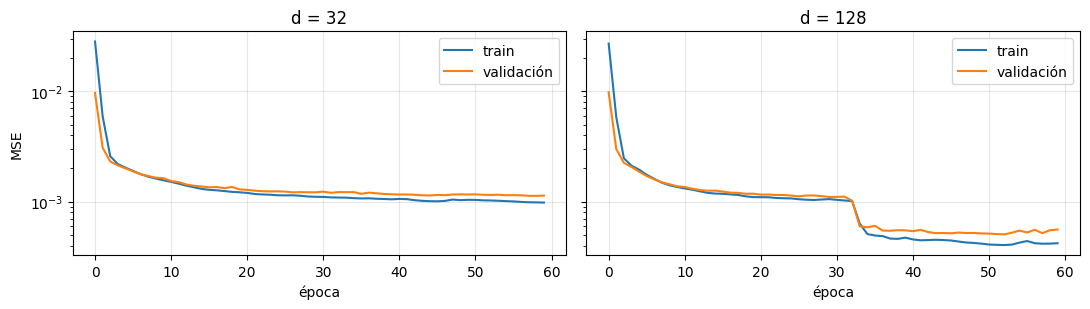

,params_total,best_epoch,train_time_s,infer_time_val_s,val_mse,val_ssim,val_gradient,val_score
latent_dim,,,,,,,,
32,725859,59,210,0.60,0.00113,0.9468,0.0037,0.0220
128,1610691,53,217,0.68,0.00051,0.9549,0.0035,0.0187


In [ ]:
# Curvas de aprendizaje (eje Y logarítmico)
fig, axes = plt.subplots(1, len(LATENT_DIMS), figsize=(11, 3.2), sharey=True)
for ax, d in zip(axes, LATENT_DIMS):
    h = results[d]["history"]
    ax.plot(h["loss"], label="train"); ax.plot(h["val_loss"], label="validación")
    ax.set_title(f"d = {d}"); ax.set_xlabel("época"); ax.set_yscale("log"); ax.grid(alpha=.3); ax.legend()
axes[0].set_ylabel("MSE")
plt.tight_layout(); plt.show()

# Tabla resumen (también en CSV)
import pandas as pd
cols = ["latent_dim", "params_total", "best_epoch", "train_time_s", "infer_time_val_s",
        "val_mse", "val_ssim", "val_gradient", "val_score"]
table = pd.DataFrame([{c: results[d][c] for c in cols} for d in LATENT_DIMS]).set_index("latent_dim")
table.to_csv(os.path.join(RESULTS_DIR, "parte1_tabla.csv"))
table.style.format({"train_time_s": "{:.0f}", "infer_time_val_s": "{:.2f}", "val_mse": "{:.5f}",
                    "val_ssim": "{:.4f}", "val_gradient": "{:.4f}", "val_score": "{:.4f}"})

## Reconstrucciones y mapas de error
Con las 512 imágenes fijas, mostramos original, reconstrucción y mapa de error (negro = sin error, amarillo = mucho) para d = 32 y d = 128. Se eligen las 3 mejores, 2 medianas y 3 peores según el error con d = 32 (aciertos y fallos).

**Qué se observa:**
- **Mejores:** rectas sin bordillos, casi idénticas al original.
- **Peores:** curvas con **bordillos rojo/blanco**, que salen como una franja rosa difusa (el promedio de rojo y blanco: efecto típico del MSE). d = 128 lo hace algo mejor.
- **Indicador verde:** d = 32 no lo reconstruye; d = 128 sí.
- **Hierba:** los cuadrados claros se suavizan en ambos.
- La **forma de la pista y el coche** se conservan siempre.

d=32: métricas sobre imágenes de evaluación fijas → {'score': 0.02225, 'ssim': 0.94626, 'gradient': 0.00378, 'mse': 0.00114}
d=128: métricas sobre imágenes de evaluación fijas → {'score': 0.01912, 'ssim': 0.95398, 'gradient': 0.00355, 'mse': 0.00052}


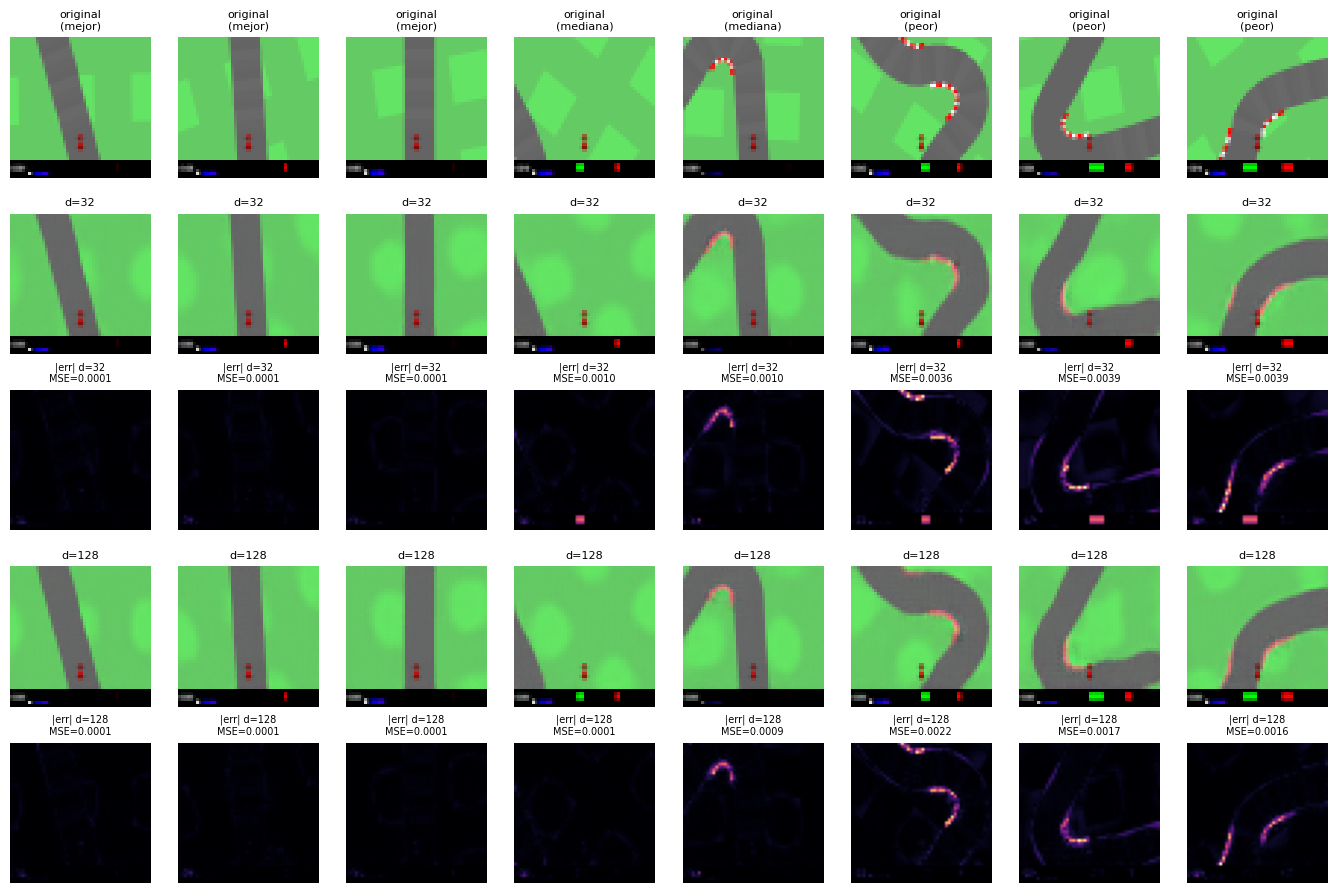

In [7]:
# Reconstrucciones de las 512 imágenes fijas (models[d][0] = autoencoder)
recs = {d: np.clip(models[d][0].predict(X_eval, batch_size=512, verbose=0), 0, 1) for d in LATENT_DIMS}
for d in LATENT_DIMS:
    print(f"d={d}: métricas sobre imágenes de evaluación fijas →",
          {k: round(v, 5) for k, v in visual_metrics(X_eval, recs[d]).items()})

# Ordenar por MSE con d=32: 3 mejores, 2 medianas, 3 peores
per_img = ((X_eval - recs[LATENT_DIMS[0]]) ** 2).mean(axis=(1, 2, 3))
order = np.argsort(per_img)
show = list(order[:3]) + list(order[len(order)//2:len(order)//2 + 2]) + list(order[-3:])
labels = ["mejor"] * 3 + ["mediana"] * 2 + ["peor"] * 3

# Fila 1: original. Después, por cada d: reconstrucción y mapa de error
rows = 1 + 2 * len(LATENT_DIMS)
fig, axes = plt.subplots(rows, len(show), figsize=(1.7 * len(show), 1.8 * rows))
for c, (k, lab) in enumerate(zip(show, labels)):
    axes[0, c].imshow(X_eval[k], interpolation="nearest"); axes[0, c].set_title(f"original\n({lab})", fontsize=8)
    for r, d in enumerate(LATENT_DIMS):
        err = np.abs(X_eval[k] - recs[d][k]).mean(-1)
        axes[1 + 2*r, c].imshow(recs[d][k], interpolation="nearest")
        axes[1 + 2*r, c].set_title(f"d={d}", fontsize=8)
        axes[2 + 2*r, c].imshow(err, cmap="magma", vmin=0, vmax=0.5)
        axes[2 + 2*r, c].set_title(f"|err| d={d}\nMSE={((X_eval[k]-recs[d][k])**2).mean():.4f}", fontsize=7)
for a in axes.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

En la fila que representa el error en d = 32 se puede ver cómo no se reconstruye la barra verde mientras que en d = 128 si, lo que representa la caída brusca en MSE que se veía en las gráficas anteriores. Aquí se ve claramente como el tamaño del vector afecta a la reconstrucción, ya que d = 32 tuvo que descartar ese detalle que d = 128 tuvo espacio para representar.

### Mapa de error medio
Error medio por píxel sobre las 512 imágenes (misma escala de color en ambos). El error se concentra en la barra inferior: con d = 32 hay una zona caliente en el indicador de dirección que con d = 128 casi desaparece. Esa barra contiene información de velocidad y giro que el predictor necesitará, así que perderla importa aunque el MSE parezca pequeño.

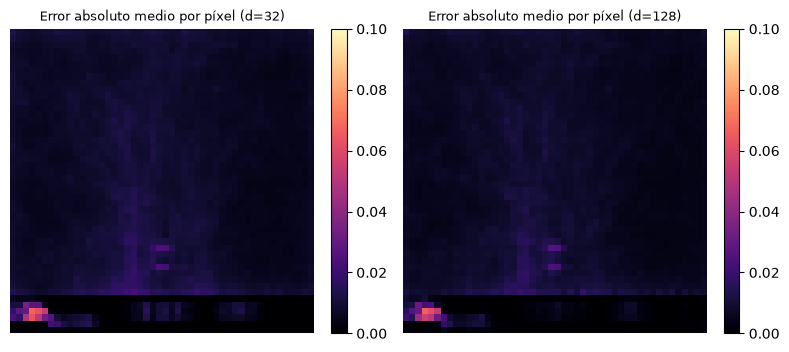

In [17]:
# Si es una sesión nueva, recalcula las reconstrucciones desde los modelos guardados
LATENT_DIMS = globals().get("LATENT_DIMS", [32, 128])
if "recs" not in globals():
    X_eval = np.load(os.path.join(DATA_DIR, "eval_images.npz"))["images"].astype("float32") / 255.0
    recs = {}
    for d in LATENT_DIMS:
        enc_l = keras.models.load_model(os.path.join(MODEL_DIR, f"encoder_d{d}.keras"))
        dec_l = keras.models.load_model(os.path.join(MODEL_DIR, f"decoder_d{d}.keras"))
        recs[d] = np.clip(dec_l.predict(enc_l.predict(X_eval, verbose=0), verbose=0), 0, 1)

# Error medio por píxel (misma escala de color en ambos)
fig, axes = plt.subplots(1, len(LATENT_DIMS), figsize=(4 * len(LATENT_DIMS), 3.5))
for ax, d in zip(axes, LATENT_DIMS):
    im = ax.imshow(np.abs(X_eval - recs[d]).mean(axis=(0, -1)), cmap="magma", vmin=0, vmax=0.1)
    ax.set_title(f"Error absoluto medio por píxel (d={d})", fontsize=9); ax.axis("off")
    plt.colorbar(im, ax=ax, fraction=.046)
plt.tight_layout(); plt.show()

### Comprobación de los modelos guardados
Cargamos `encoder_d{d}.keras` y `decoder_d{d}.keras` desde disco, codificamos 64 imágenes (→ `(64, d)`), las decodificamos (→ `(64, 48, 48, 3)`) y verificamos que coincide con el autoencoder en memoria.

In [19]:
# Los modelos guardados funcionan por separado y reproducen el resultado
for d in LATENT_DIMS:
    enc_l = keras.models.load_model(os.path.join(MODEL_DIR, f"encoder_d{d}.keras"))
    dec_l = keras.models.load_model(os.path.join(MODEL_DIR, f"decoder_d{d}.keras"))
    z = enc_l.predict(X_eval[:64], verbose=0)      # (64, d)
    rec = dec_l.predict(z, verbose=0)              # (64, 48, 48, 3)
    assert z.shape == (64, d) and rec.shape == (64, 48, 48, 3)
    assert np.allclose(rec, recs[d][:64], atol=1e-4)
    print(f"encoder_d{d}.keras + decoder_d{d}.keras  latente {z.shape}")
print("Ficheros guardados:", sorted(os.listdir(MODEL_DIR)))

encoder_d32.keras + decoder_d32.keras  latente (64, 32)
encoder_d128.keras + decoder_d128.keras  latente (64, 128)
Ficheros guardados: ['ae_d128_best.weights.h5', 'ae_d32_best.weights.h5', 'decoder_d128.keras', 'decoder_d32.keras', 'encoder_d128.keras', 'encoder_d32.keras']


## Conclusiones

| | Parámetros | Mejor época | Entreno | MSE val | SSIM val | Score val |
|---|---|---|---|---|---|---|
| d = 32 | 725 859 | 59 | 210 s | 0,00113 | 0,947 | 0,0220 |
| d = 128 | 1 610 691 | 53 | 217 s | **0,00051** | **0,955** | **0,0187** |
| Repetir última imagen (24 pasos) | 0 | — | — | 0,0156 | 0,751 | 0,101 |

- **Tamaño latente:** d = 128 reduce el MSE a menos de la mitad con 2,2× parámetros y casi el mismo tiempo. La mejora viene de que el vector más grande es capaz de guardar la información sobre indicador de dirección para poder reconstruirla. Como es una sola semilla es probable que d = 32 no lo aprendiera en 60 epochs pero no podemos afirmar que sea incapaz.
- **Información perdida:** se reconstruyen la pista y el coche casi perfectamente pero se pierden detalles finos que se suavizan (bordillos, textura de hierba) y, con d = 32, el indicador de dirección. El MSE favorece imágenes "promedio".
- **Elección final:** d = 128 es capaz de reconstruir la imagen mucho mas fielmente que d = 32, por lo que se escoge como mejor. Aun asi, a la hora de predecir acciones en partes futuras las imágenes van a pasar por el mismo decoder por lo que la capacidad de reconstrucción es el límite mínimo de error que puede alcanzar.

## Declaración de ayuda externa e IA
Se usó Claude (Anthropic) como asistente para generar la estructura inicial del código, explicar el enunciado y los ficheros proporcionados, y redactar borradores de explicaciones. El grupo revisó, ejecutó y validó el código, y comprobó los resultados e interpretaciones sobre las salidas del notebook. Se usaron los ficheros del profesor (`dataset.py`, `carracing48.py`, `metric.py`) sin modificarlos.

_Adaptar a lo que se haya usado realmente._